In [ ]:
# Personal Expense Tracker and Spending Analysis

## Project Overview

This project is a Python-based expense tracker that records personal expenses, stores them in a CSV file, and analyses spending patterns using Pandas.

## Features
- Records expenses and categorises transactions.
- Saves expense records to a CSV file.
- Calculates total and average expenditure.
- Groups spending by category.
- Identifies the highest-spending category.
- Calculates spending percentages.
- Generates visualisations using Matplotlib.
- Produces automated spending insights.

## Technologies Used
- Python
- Pandas
- Matplotlib
- CSV

## Learning Outcomes

Through this project, I practised Python fundamentals, including loops, dictionaries, conditional statements, functions and file handling, alongside introductory data analysis and visualisation.

In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [3]:
import csv


In [4]:

expenses = []

answer = "yes"

while answer == "yes":
    new_expense = {
        "name": input("Enter expense name:"),
        "category": input("Enter category:"),
        "amount": float(input("Enter amount:"))
    }

    expenses.append(new_expense)
    answer = input("Do you want to add new expense:").strip().lower()

# Calculate the total
total_spent = 0

for expense in expenses:
    total_spent += expense["amount"]

# Calculate spending per category
category_totals = {}

for expense in expenses:
    category = expense["category"]

    if category in category_totals:
        category_totals[category] += expense["amount"]
    else:
        category_totals[category] = expense["amount"]

print("Spending by category:", category_totals)
print("Total spent:", total_spent)


Enter expense name: GROCERIES
Enter category: FOOD
Enter amount: 400
Do you want to add new expense: YES
Enter expense name: CLOTHES
Enter category: PERSONAL
Enter amount: 4000
Do you want to add new expense: YES
Enter expense name: BOOKS
Enter category: SCHOOL
Enter amount: 4999
Do you want to add new expense: YES
Enter expense name: BOOKS
Enter category: SCHOOL
Enter amount: 400
Do you want to add new expense: NO


Spending by category: {'FOOD': 400.0, 'PERSONAL': 4000.0, 'SCHOOL': 5399.0}
Total spent: 9799.0


In [5]:
with open("expenses.csv", "w", newline="") as file:
    writer = csv.DictWriter(file, fieldnames=["name", "category", "amount"])

    writer.writeheader()
    writer.writerows(expenses)

In [6]:
import os
print(os.listdir())

['.virtual_documents', 'expenses.csv']


In [9]:


with open("expenses.csv", "r") as file:
    reader = csv.DictReader(file)

    saved_expenses = list(reader)

print(saved_expenses)
import pandas as pd
df=pd.DataFrame(saved_expenses)
print(df)

[{'name': 'GROCERIES', 'category': 'FOOD', 'amount': '400.0'}, {'name': 'CLOTHES', 'category': 'PERSONAL', 'amount': '4000.0'}, {'name': 'BOOKS', 'category': 'SCHOOL', 'amount': '4999.0'}, {'name': 'BOOKS', 'category': 'SCHOOL', 'amount': '400.0'}]
        name  category  amount
0  GROCERIES      FOOD   400.0
1    CLOTHES  PERSONAL  4000.0
2      BOOKS    SCHOOL  4999.0
3      BOOKS    SCHOOL   400.0


In [10]:
for expense in saved_expenses:
    expense["amount"] = float(expense["amount"])

print(saved_expenses)

[{'name': 'GROCERIES', 'category': 'FOOD', 'amount': 400.0}, {'name': 'CLOTHES', 'category': 'PERSONAL', 'amount': 4000.0}, {'name': 'BOOKS', 'category': 'SCHOOL', 'amount': 4999.0}, {'name': 'BOOKS', 'category': 'SCHOOL', 'amount': 400.0}]


In [11]:
df.head()

,name,category,amount
0,GROCERIES,FOOD,400.0
1,CLOTHES,PERSONAL,4000.0
2,BOOKS,SCHOOL,4999.0
3,BOOKS,SCHOOL,400.0


In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4 entries, 0 to 3
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   name      4 non-null      object
 1   category  4 non-null      object
 2   amount    4 non-null      object
dtypes: object(3)
memory usage: 228.0+ bytes


In [14]:
df.describe()

,name,category,amount
count,4,4,4
unique,3,3,3
top,BOOKS,SCHOOL,400.0
freq,2,2,2


category
FOOD         400.0
PERSONAL    4000.0
SCHOOL      5399.0
Name: amount, dtype: float64


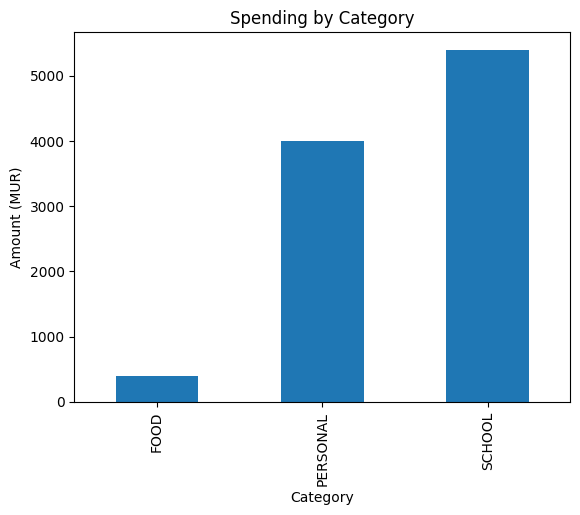

In [15]:
df["amount"] = pd.to_numeric(df["amount"])
category_summary = df.groupby("category")["amount"].sum()

print(category_summary)
import matplotlib.pyplot as plt
category_summary.plot(kind="bar")

plt.title("Spending by Category")
plt.xlabel("Category")
plt.ylabel("Amount (MUR)")
plt.show()

In [16]:
average_spending_per_category=df.groupby("category")["amount"].mean()
print("Average expenditure per category:")
print(average_spending_per_category)

Average expenditure per category:
category
FOOD         400.0
PERSONAL    4000.0
SCHOOL      2699.5
Name: amount, dtype: float64


In [17]:
highest_category=category_summary.idxmax()
highest_amount=category_summary.max()
print("Your highest spending category is:",highest_category)
print("Amount spent in MUR:",highest_amount)

Your highest spending category is: SCHOOL
Amount spent in MUR: 5399.0


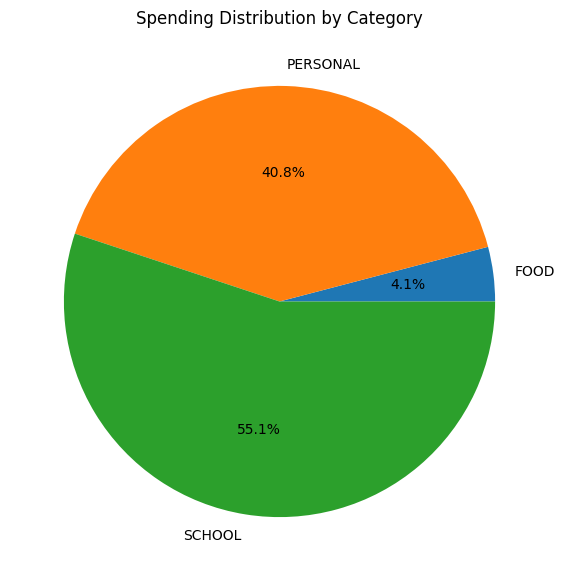

In [18]:
category_summary.plot(
    kind="pie",
    autopct="%1.1f%%",
    figsize=(7, 7)
)

plt.title("Spending Distribution by Category")
plt.ylabel("")
plt.show()

In [23]:
number_of_transactions=len(expenses)
average_transaction=total_spent/number_of_transactions
category_percentages=(category_summary/total_spent)*100
print("Category spending percentages:",category_percentages.round(2))
print("Total transactions:",number_of_transactions)
print("Average transactions:MUR",average_transaction)

Category spending percentages: category
FOOD         4.08
PERSONAL    40.82
SCHOOL      55.10
Name: amount, dtype: float64
Total transactions: 4
Average transactions:MUR 2449.75


In [24]:
for category, amount in category_summary.items():
    percentage = category_percentages[category]
    print(f"{category}: MUR {amount:.2f} ({percentage:.1f}%)")

FOOD: MUR 400.00 (4.1%)
PERSONAL: MUR 4000.00 (40.8%)
SCHOOL: MUR 5399.00 (55.1%)


In [42]:
total_spent = df["amount"].sum()

number_of_transactions = len(df)

average_transaction = df["amount"].mean()

category_summary = df.groupby("category")["amount"].sum()

highest_category = category_summary.idxmax()

highest_amount = category_summary.max()

category_percentages = (category_summary / total_spent) * 100

In [59]:
def generate_report(df):
    if df.empty:
        print("No expenses recorded yet.")
        return
    if total_spent > 0:
        category_percentages = (category_summary / total_spent) * 100
    else:
        category_percentages = category_summary * 0
    print("*********************************")
    print("    PERSONAL EXPENSES REPORT")
    print("*********************************")
    print("Total transactions:",number_of_transactions,)
    print("Average transactions:MUR",average_transaction)
    print('Highest spent category:',highest_category)
    print("Amount spent in that category:MUR",highest_amount)
    print("***********************************")

    print("\nSPENDING BY CATEGORY")
    print("----------------------------")

    for category, amount in category_summary.items():
        percentage = category_percentages[category]

        print(f"{category}: MUR {amount:.2f} ({percentage:.1f}%)")

    if highest_amount > total_spent * 0.5:
        print("\nINSIGHT: More than half of your spending is in", highest_category)
    else:
        print("\nINSIGHT: Your spending is distributed across multiple categories.")
        print("\nSPENDING INSIGHT")
    print(f"{highest_category} accounts for {category_percentages[highest_category]:.1f}% of your total spending.")

    average_category_spending = category_summary.mean()

    print("\n*CATEGORY INSIGHTS*")

    for category, amount in category_summary.items():
        if amount < average_category_spending:
            print(f"{category}: Below average spending")
        elif amount > average_category_spending:
            print(f"{category}: Above average spending")
        else:
            print(f"{category}: Average spending")

generate_report(df)

*********************************
    PERSONAL EXPENSES REPORT
*********************************
Total transactions: 4
Average transactions:MUR 2449.75
Highest spent category: SCHOOL
Amount spent in that category:MUR 5399.0
***********************************

SPENDING BY CATEGORY
----------------------------
FOOD: MUR 400.00 (4.1%)
PERSONAL: MUR 4000.00 (40.8%)
SCHOOL: MUR 5399.00 (55.1%)

INSIGHT: More than half of your spending is in SCHOOL
SCHOOL accounts for 55.1% of your total spending.

*CATEGORY INSIGHTS*
FOOD: Below average spending
PERSONAL: Above average spending
SCHOOL: Above average spending


In [47]:
def show_total():
    return "Your total has been calculated!"
